In [1]:
from __future__ import annotations
import random
from typing import Sequence, List
import matplotlib.pyplot as plt
import numpy as np

class Child:
    _name: str
    _carateristics: tuple[bool, ...]

    def __init__(self, name: str, carateristics: Sequence[bool]):
        self._name = name
        self._carateristics = tuple(carateristics)

    def difference(self, other: Child) -> int:
        """Calcola la distanza di Hamming (numero di caratteristiche diverse)."""
        return sum(s != o for s, o in zip(self._carateristics, other._carateristics))

    def __str__(self) -> str:
        return f"{self._name}: {self._carateristics}"

    def __repr__(self) -> str:
        return self._name

In [2]:
def fitness(solution: Sequence[Child]) -> int:
    """
    Calcola la somma delle differenze tra bambini adiacenti nel cerchio.
    L'ultimo elemento si confronta con il primo: (i + 1) % n.
    """
    sol = list(solution)
    total_diff = 0
    n = len(sol)
    for i in range(n):
        c1 = sol[i]
        c2 = sol[(i + 1) % n]
        total_diff += c1.difference(c2)
    return total_diff


def canonicalize(solution: List[Child]) -> List[Child]:
    """
    Elimina la simmetria di riflessione (senso orario vs antiorario).
    Presuppone che il primo bambino (solution[0]) sia sempre fisso.
    
    Se il vicino a destra (solution[1]) ha un identificativo maggiore
    del vicino a sinistra (solution[-1]), inverte la sequenza interna.
    """
    if len(solution) <= 2:
        return solution
    
    if solution[1]._name > solution[-1]._name:
        return [solution[0]] + list(reversed(solution[1:]))
    return solution

In [3]:
def mutate_swap(parent: List[Child]) -> List[Child]:
    """Scambia due bambini a caso tra gli indici [1, N-1]. Arità: 1."""
    child = parent.copy()
    i, j = random.sample(range(1, len(child)), 2)
    child[i], child[j] = child[j], child[i]
    return canonicalize(child)


def mutate_inversion(parent: List[Child]) -> List[Child]:
    """Inverte una sequenza contigua (2-opt) tra gli indici [1, N-1]. Arità: 1."""
    child = parent.copy()
    i, j = sorted(random.sample(range(1, len(child)), 2))
    child[i:j+1] = list(reversed(child[i:j+1]))
    return canonicalize(child)


def crossover_ox(parent1: List[Child], parent2: List[Child]) -> List[Child]:
    """Order Crossover (OX) preservando l'ordine relativo. Arità: 2."""
    n = len(parent1)
    i, j = sorted(random.sample(range(1, n), 2))
    
    child: list[Child | None] = [parent1[0]] + [None] * (n - 1)
    child[i:j+1] = parent1[i:j+1]
    
    p2_remaining = [c for c in parent2[1:] if c not in child[i:j+1]]
    fill_idx = (j + 1) % n
    if fill_idx == 0:
        fill_idx = 1
        
    for c in p2_remaining:
        while child[fill_idx] is not None:
            fill_idx = (fill_idx + 1) % n
            if fill_idx == 0:
                fill_idx = 1
        child[fill_idx] = c
        
    return canonicalize(child)  # type: ignore


def tournament_selection(
    population: List[List[Child]], 
    fitness_values: List[int], 
    tournament_size: int = 3
) -> List[Child]:
    """Seleziona tau individui a caso ed estrae il migliore (Slide 61)."""
    selected_indices = random.sample(range(len(population)), tournament_size)
    best_idx = max(selected_indices, key=lambda idx: fitness_values[idx])
    return population[best_idx]

In [4]:
NUM_CHILDREN = 30  # N bambini
NUM_C = 15         # C caratteristiche booleane

random.seed(42)
np.random.seed(42)

# Creazione dei bambini con caratteristiche booleane casuali
all_children: list[Child] = []
for c in range(NUM_CHILDREN):
    name = f"child_{c:02d}"
    features = random.sample([True, False], k=NUM_C, counts=[NUM_C, NUM_C])
    all_children.append(Child(name, features))

# Fissiamo il bambino di ancoraggio
FIRST_CHILD = all_children[0]
REST_OF_CHILDREN = all_children[1:].copy()

def make_random_individual() -> List[Child]:
    shuffled_rest = list(REST_OF_CHILDREN)
    random.shuffle(shuffled_rest)
    return canonicalize([FIRST_CHILD] + shuffled_rest)

# Iperparametri dell'algoritmo evolutivo
POPULATION_SIZE = 50   # mu (genitori/popolazione stabile)
OFFSPRING_SIZE = 30    # lambda (figli generati per generazione)
GENERATIONS = 300      # Condizione di terminazione
TOURNAMENT_SIZE = 3    # tau (pressione selettiva)

# Inizializzazione popolazione iniziale
population = [make_random_individual() for _ in range(POPULATION_SIZE)]
fitness_values = [fitness(ind) for ind in population]

In [5]:
history_gen = [0]
history_best_fitness = [max(fitness_values)]
history_avg_fitness = [float(np.mean(fitness_values))]

print(f"Gen 000 | Best Fitness: {history_best_fitness[0]} | Avg: {history_avg_fitness[0]:.2f}")

for gen in range(1, GENERATIONS + 1):
    offspring_population: List[List[Child]] = []
    
    for _ in range(OFFSPRING_SIZE):
        r = random.random()
        
        # 1. Scelta operatore tramite soglie di probabilità (Slide 68)
        if r < 0.45:
            # Crossover OX (45%): richiede 2 genitori
            p1 = tournament_selection(population, fitness_values, TOURNAMENT_SIZE)
            p2 = tournament_selection(population, fitness_values, TOURNAMENT_SIZE)
            child = crossover_ox(p1, p2)
            
        elif r < 0.80:
            # Inversion Mutation (35%): richiede 1 genitore
            p = tournament_selection(population, fitness_values, TOURNAMENT_SIZE)
            child = mutate_inversion(p)
            
        else:
            # Swap Mutation (20%): richiede 1 genitore
            p = tournament_selection(population, fitness_values, TOURNAMENT_SIZE)
            child = mutate_swap(p)
            
        offspring_population.append(child)
        
    # Valutazione della fitness dei figli
    offspring_fitness = [fitness(child) for child in offspring_population]
    
    # Survivor Selection (mu + lambda): competizione tra genitori e figli (Slide 52, 63)
    combined_pop = population + offspring_population
    combined_fit = fitness_values + offspring_fitness
    
    # Conserviamo i migliori POPULATION_SIZE individui
    survivor_indices = sorted(
        range(len(combined_fit)), 
        key=lambda idx: combined_fit[idx], 
        reverse=True
    )[:POPULATION_SIZE]
    
    population = [combined_pop[idx] for idx in survivor_indices]
    fitness_values = [combined_fit[idx] for idx in survivor_indices]
    
    # Salvataggio metriche per generazione
    history_gen.append(gen)
    history_best_fitness.append(fitness_values[0])
    history_avg_fitness.append(float(np.mean(fitness_values)))
    
    if gen % 50 == 0 or gen == 1:
        print(f"Gen {gen:03d} | Best Fitness: {fitness_values[0]} | Avg: {np.mean(fitness_values):.2f}")

Gen 000 | Best Fitness: 246 | Avg: 224.68
Gen 001 | Best Fitness: 258 | Avg: 234.60
Gen 050 | Best Fitness: 294 | Avg: 289.64
Gen 100 | Best Fitness: 308 | Avg: 304.36
Gen 150 | Best Fitness: 314 | Avg: 312.24
Gen 200 | Best Fitness: 318 | Avg: 316.60
Gen 250 | Best Fitness: 318 | Avg: 318.00
Gen 300 | Best Fitness: 320 | Avg: 319.64



MIGLIOR FITNESS FINALE: 320
DISPOSIZIONE NEL CERCHIO:
child_00 -> child_08 -> child_01 -> child_09 -> child_16 -> child_24 -> child_10 -> child_27 -> child_25 -> child_14 -> child_19 -> child_17 -> child_18 -> child_06 -> child_12 -> child_21 -> child_20 -> child_15 -> child_02 -> child_05 -> child_04 -> child_22 -> child_23 -> child_26 -> child_11 -> child_03 -> child_07 -> child_29 -> child_28 -> child_13 -> (chiude su child_00)


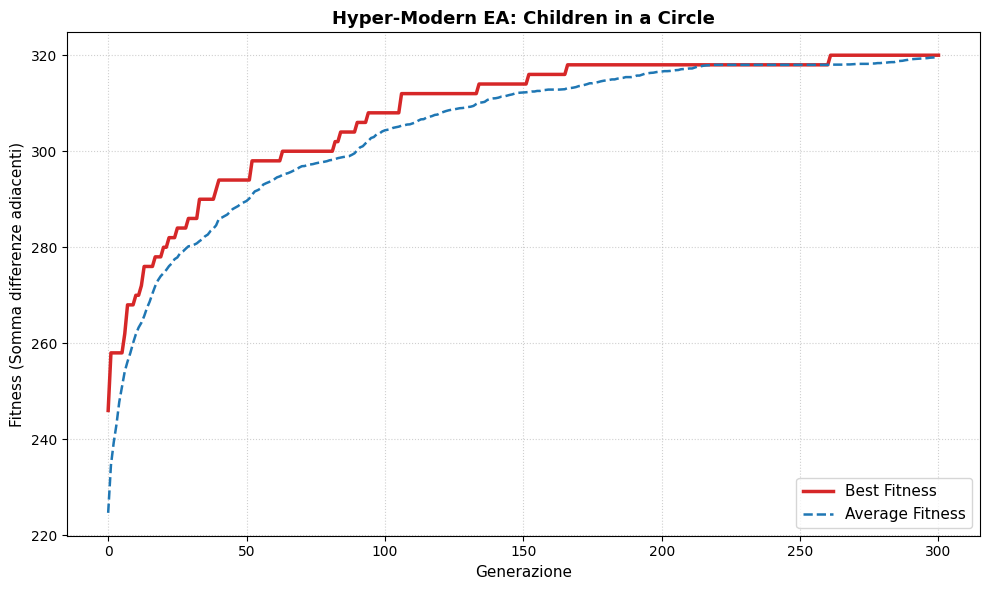

In [6]:
best_solution = population[0]

print("\n" + "=" * 65)
print(f"MIGLIOR FITNESS FINALE: {fitness_values[0]}")
print("DISPOSIZIONE NEL CERCHIO:")
print(" -> ".join(c._name for c in best_solution) + f" -> (chiude su {best_solution[0]._name})")
print("=" * 65)

# Visualizzazione grafica dell'andamento
plt.figure(figsize=(10, 6))
plt.plot(history_gen, history_best_fitness, color='#d62728', linewidth=2.5, label='Best Fitness')
plt.plot(history_gen, history_avg_fitness, color='#1f77b4', linestyle='--', linewidth=1.8, label='Average Fitness')

plt.title("Hyper-Modern EA: Children in a Circle", fontsize=13, fontweight='bold')
plt.xlabel("Generazione", fontsize=11)
plt.ylabel("Fitness (Somma differenze adiacenti)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()